# 🟠 3. Deep Dive: Word Embeddings & Sampling Strategies

### *Dense Embedding Spaces, Bidirectional RNNs, and Temperature-Scaled Text Generation Dynamics*

---

## 📌 Module Overview
1. **Word Representations**:
   - One-Hot Sparsity vs. Dense Embedding Vectors ($\mathbb{R}^{|V|} 	o \mathbb{R}^D$).
   - Embedding matrix lookup mechanics ($E \in \mathbb{R}^{V 	imes D}$).
2. **Bidirectional Recurrent Architectures**:
   - Forward state ($\overrightarrow{h}_t$) + Backward state ($\overleftarrow{h}_t$).
   - When to use Bidirectional (Classification, NER) vs. When NOT to use (Autoregressive generation).
3. **Text Decoding & Sampling Strategies**:
   - **Greedy Decoding ($rg\max$)**: Robotic, repetitive loops.
   - **Temperature-Scaled Softmax**: Controlling randomness and creativity.
     $$P(w_i) = rac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$$
   - **Top-K & Top-P (Nucleus) Filtering**.
4. **Perplexity (PPL)**: The intrinsic metric for language models.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
SEED = 42
np.random.seed(SEED)
print("Deep Dive environment ready.")


Deep Dive environment ready.


## 1. Temperature-Scaled Softmax Sampling
When an autoregressive model outputs raw logits $\mathbf{z} \in \mathbb{R}^V$, the temperature parameter $T > 0$ controls the flatness of the resulting probability distribution:
* **$T 	o 0$ (Low Temperature, e.g., $T = 0.2$)**: Sharpen the distribution. High-probability tokens dominate; produces safe, deterministic, repetitive text.
* **$T = 1.0$**: Standard unscaled categorical distribution.
* **$T > 1.0$ (High Temperature, e.g., $T = 1.5$)**: Flatten the distribution toward uniform entropy. Allows rare, unexpected words to be chosen; produces highly creative (or chaotic) text.


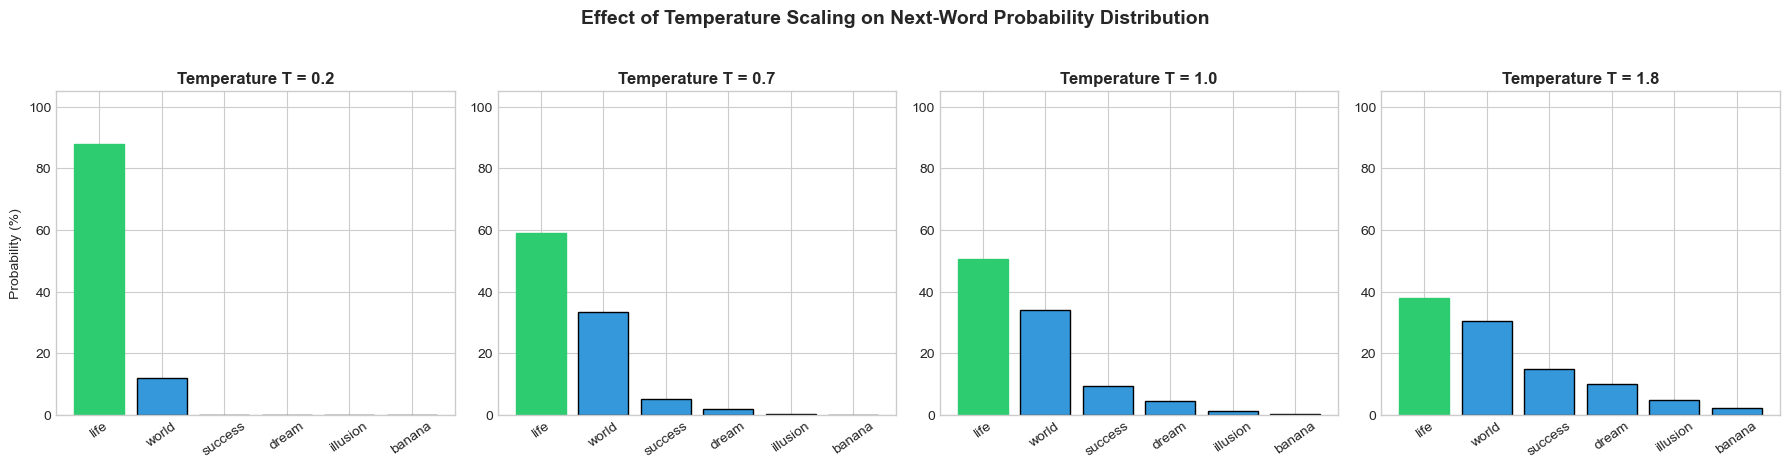

In [2]:
# Visualizing Temperature Scaling on Output Logits
candidate_words = ['life', 'world', 'success', 'dream', 'illusion', 'banana']
# Hypothetical raw output logits from model head
logits = np.array([4.2, 3.8, 2.5, 1.8, 0.5, -1.0])

temperatures = [0.2, 0.7, 1.0, 1.8]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for idx, (ax, T) in enumerate(zip(axes, temperatures)):
    # Apply Temperature scaling
    scaled = logits / T
    exp_scaled = np.exp(scaled - np.max(scaled))
    probs = exp_scaled / np.sum(exp_scaled)

    bars = ax.bar(candidate_words, probs * 100, color='#3498db', edgecolor='black')
    ax.set_title(f"Temperature T = {T}", fontweight='bold')
    ax.set_ylabel('Probability (%)' if idx == 0 else "")
    ax.set_ylim(0, 105)
    ax.set_xticklabels(candidate_words, rotation=35)

    # Highlight top token
    bars[0].set_color('#2ecc71')

plt.suptitle('Effect of Temperature Scaling on Next-Word Probability Distribution', y=1.03, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
